In [2]:
import random
import pylab as plt
import hashlib

In [6]:
def generate_random_number_dataset(size):
  dataset = []
  for i in range(size):
    dataset.append(random.randrange(0,2**32))
  return dataset

assert len(generate_random_number_dataset(10)) == 10

In [ ]:
def count_zeros(str_bin):
  str_bin = str_bin[::-1]
  leadzeros = 0
  for i in str_bin:
    if i == str(1):
      break
    else:
      leadzeros += 1
  return leadzeros

assert 0 == count_zeros(bin(7))
assert 0 == count_zeros(bin(1))
assert 1 == count_zeros(bin(2))
assert 4 == count_zeros(bin(16))
assert 3 == count_zeros(bin(53130088456))

In [3]:
def hash_bin(key,k):
  key = repr(key).encode()
  return (int(hashlib.md5(key).hexdigest(),16) % k)

In [4]:
def variance(data,mean):
  total = 0
  for i in data:
    total += (i-mean)**2
  return total/len(data)

In [22]:
def test_uniformity(k,data):
  hash_values = []
  for i in data:
    hash_values.append(hash_bin(i,k))
  value_to_count = {}
  for i in hash_values:
    if i not in value_to_count.keys():
      value_to_count[i] = hash_values.count(i)
  plt.plot([i for i in range(k)],list(value_to_count.values()))
  variance_val = variance(value_to_count.values(),len(data)/k)
  return variance_val**0.5

7.107080976040726

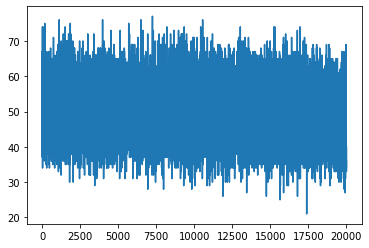

In [26]:
test_uniformity(20000,generate_random_number_dataset(1000000))